In [88]:
names = open('names.txt','r').read().split()

names[:20]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn',
 'abigail',
 'emily',
 'elizabeth',
 'mila',
 'ella',
 'avery',
 'sofia',
 'camila',
 'aria',
 'scarlett']

In [89]:
print(min(len(w) for w in names))

print(max(len(w) for w in names))

2
15


In [90]:
bigram_count = {}
for w in names:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs,chs[1:]):
        bigram = (ch1,ch2)
        bigram_count[bigram] = bigram_count.get(bigram,0) + 1

In [91]:
sorted(bigram_count.items(), key = lambda kv: -kv[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [92]:
import torch

Names = torch.zeros((27,27), dtype=torch.int32)

In [93]:
alphabet = sorted(list(set(''.join(names))))

stoi = {s:i+1 for i,s in enumerate(alphabet)}
stoi['.'] = 0
stoi

itos = {i:s for s,i in stoi.items()}
itos

{1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z',
 0: '.'}

In [94]:
for w in names:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs,chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        Names[ix1,ix2] += 1

Names

tensor([[   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
         1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
          134,  535,  929],
        [6640,  556,  541,  470, 1042,  692,  134,  168, 2332, 1650,  175,  568,
         2528, 1634, 5438,   63,   82,   60, 3264, 1118,  687,  381,  834,  161,
          182, 2050,  435],
        [ 114,  321,   38,    1,   65,  655,    0,    0,   41,  217,    1,    0,
          103,    0,    4,  105,    0,    0,  842,    8,    2,   45,    0,    0,
            0,   83,    0],
        [  97,  815,    0,   42,    1,  551,    0,    2,  664,  271,    3,  316,
          116,    0,    0,  380,    1,   11,   76,    5,   35,   35,    0,    0,
            3,  104,    4],
        [ 516, 1303,    1,    3,  149, 1283,    5,   25,  118,  674,    9,    3,
           60,   30,   31,  378,    0,    1,  424,   29,    4,   92,   17,   23,
            0,  317,    1],
        [3983,  679,  121,  153,  384, 1271,   82,

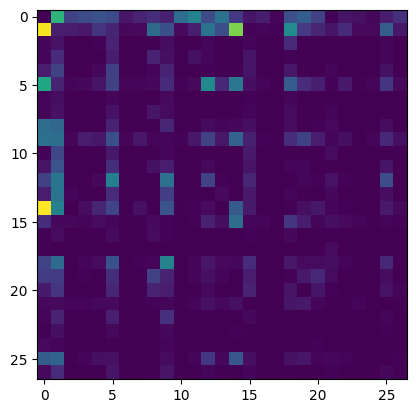

In [95]:
# Plotting out visual of array
import matplotlib.pyplot as plt

plt.imshow(Names)

In [96]:
# Taking Names[0] and turning counts into probabilites
# Names[0] is the first character to start a name 

Names[0]
p = Names[0] / sum(Names[0])
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [132]:
# normalizing each row into a PDF

P = (Names+1).float() # making copy
P /= P.sum(1, keepdims=True)
P

tensor([[3.1192e-05, 1.3759e-01, 4.0767e-02, 4.8129e-02, 5.2745e-02, 4.7785e-02,
         1.3038e-02, 2.0898e-02, 2.7293e-02, 1.8465e-02, 7.5577e-02, 9.2452e-02,
         4.9064e-02, 7.9195e-02, 3.5777e-02, 1.2321e-02, 1.6095e-02, 2.9008e-03,
         5.1154e-02, 6.4130e-02, 4.0830e-02, 2.4641e-03, 1.1759e-02, 9.6070e-03,
         4.2109e-03, 1.6719e-02, 2.9008e-02],
        [1.9583e-01, 1.6425e-02, 1.5983e-02, 1.3889e-02, 3.0756e-02, 2.0435e-02,
         3.9809e-03, 4.9835e-03, 6.8796e-02, 4.8685e-02, 5.1899e-03, 1.6779e-02,
         7.4575e-02, 4.8213e-02, 1.6039e-01, 1.8872e-03, 2.4475e-03, 1.7988e-03,
         9.6279e-02, 3.2997e-02, 2.0288e-02, 1.1264e-02, 2.4623e-02, 4.7771e-03,
         5.3963e-03, 6.0480e-02, 1.2857e-02],
        [4.3039e-02, 1.2051e-01, 1.4596e-02, 7.4850e-04, 2.4701e-02, 2.4551e-01,
         3.7425e-04, 3.7425e-04, 1.5719e-02, 8.1587e-02, 7.4850e-04, 3.7425e-04,
         3.8922e-02, 3.7425e-04, 1.8713e-03, 3.9671e-02, 3.7425e-04, 3.7425e-04,
         3.1549e-

In [133]:
# Sampling from the pdf of p
g = torch.Generator().manual_seed(2147483647)

# name generating loop

out = []
for i in range(10):
    idx = 0
    name = ''
    while True:
        p = P[idx]
        idx = torch.multinomial(p, num_samples=1 , replacement=True, generator=g).item()
        name += itos[idx]
        if idx == 0:
            out.append(name)
            break

out 

['junide.',
 'janasah.',
 'p.',
 'cony.',
 'a.',
 'nn.',
 'kohin.',
 'tolian.',
 'juee.',
 'ksahnaauranilevias.']

In [134]:
# Calculating the log likelihood (measuring loss)

log_likelihood = 0
n = 0
for w in names:
        chs = ['.'] + list(w) + ['.']
        for ch1, ch2 in zip(chs,chs[1:]):
            idx1 = stoi[ch1]
            idx2 = stoi[ch2]
            prob = P[idx1,idx2]
            log_prob = torch.log(prob)
            log_likelihood += log_prob
            n += 1

nll = -log_likelihood
avg_nll_loss = nll / n
print(avg_nll_loss)

tensor(2.4543)


In [ ]:
# creating the training/testing set
xs, ys = [], []

for w in names:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs,chs[1:]):
        idx1 = stoi[ch1]
        idx2 = stoi[ch2]
        xs.append(idx1)
        ys.append(idx2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)

num = xs.nelement()
num

228145

In [153]:
import torch.nn.functional as F
xenc = F.one_hot(xs,num_classes=27).float()
xenc

tensor([[1., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 1.],
        [0., 0., 0.,  ..., 0., 1., 0.],
        [0., 0., 0.,  ..., 0., 0., 1.]])

In [171]:
# Training loop for this nn 

# random weights initalized
W = torch.randn((27,27), generator=g,requires_grad =True)

lr = 50
for k in range(150):
    # Forward pass
    logits = xenc @ W
    counts = logits.exp()
    probs = counts / counts.sum(1, keepdims=True)

    loss = -probs[torch.arange(num), ys].log().mean()

    # backward pass 
    W.grad = None 
    loss.backward()

    # Update parameters
    W.data += -lr * W.grad
    print(loss)


tensor(3.7929, grad_fn=<NegBackward0>)
tensor(3.3810, grad_fn=<NegBackward0>)
tensor(3.1331, grad_fn=<NegBackward0>)
tensor(2.9843, grad_fn=<NegBackward0>)
tensor(2.8903, grad_fn=<NegBackward0>)
tensor(2.8246, grad_fn=<NegBackward0>)
tensor(2.7766, grad_fn=<NegBackward0>)
tensor(2.7400, grad_fn=<NegBackward0>)
tensor(2.7110, grad_fn=<NegBackward0>)
tensor(2.6873, grad_fn=<NegBackward0>)
tensor(2.6676, grad_fn=<NegBackward0>)
tensor(2.6510, grad_fn=<NegBackward0>)
tensor(2.6369, grad_fn=<NegBackward0>)
tensor(2.6246, grad_fn=<NegBackward0>)
tensor(2.6139, grad_fn=<NegBackward0>)
tensor(2.6044, grad_fn=<NegBackward0>)
tensor(2.5958, grad_fn=<NegBackward0>)
tensor(2.5882, grad_fn=<NegBackward0>)
tensor(2.5812, grad_fn=<NegBackward0>)
tensor(2.5749, grad_fn=<NegBackward0>)
tensor(2.5690, grad_fn=<NegBackward0>)
tensor(2.5637, grad_fn=<NegBackward0>)
tensor(2.5587, grad_fn=<NegBackward0>)
tensor(2.5541, grad_fn=<NegBackward0>)
tensor(2.5499, grad_fn=<NegBackward0>)
tensor(2.5459, grad_fn=<N